# Machine Learning-Based Cardiometabolic Risk Stratification Using Population Health Data: An Explainable Clinical Decision Support System

## Notebook 2: Exploratory Data Analysis

**Student Name:** Vanshika Karnwal | Student ID: 201957572  
**Supervisor:** Dr Baoru Huang  
**Module:** COMP702 Dissertation | University of Liverpool  
**Dataset:** NHANES 2017-March 2020 Pre-Pandemic  
**Source:** https://wwwn.cdc.gov/nchs/nhanes/Default.aspx

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded")

Libraries loaded


In [4]:
df = pd.read_csv(r'C:\Users\VANSHIKA KARNWAL\OneDrive\Desktop\DISSERTATION\DATASETS\nhanes_final_dataset_dissertation.csv')

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nRisk Distribution:")
print(df['Risk_category'].value_counts())

Dataset shape: (3528, 22)

Columns: ['SEQN', 'Age', 'Gender', 'Race', 'Systolic_BP', 'Diastolic_BP', 'BMI', 'Waist_Circumference', 'HbA1c', 'Fasting_Glucose', 'Total_Cholesterol', 'HDL_Cholesterol', 'Triglycerides', 'LDL_Cholesterol', 'Smoking_Status', 'Total_PA_Minutes', 'Sedentary_Hours', 'Creatinine', 'Uric_Acid', 'GGT', 'eGFR', 'Risk_category']

Risk Distribution:
Risk_category
High        1470
Moderate    1391
Low          667
Name: count, dtype: int64


## 1. Risk Category Distribution

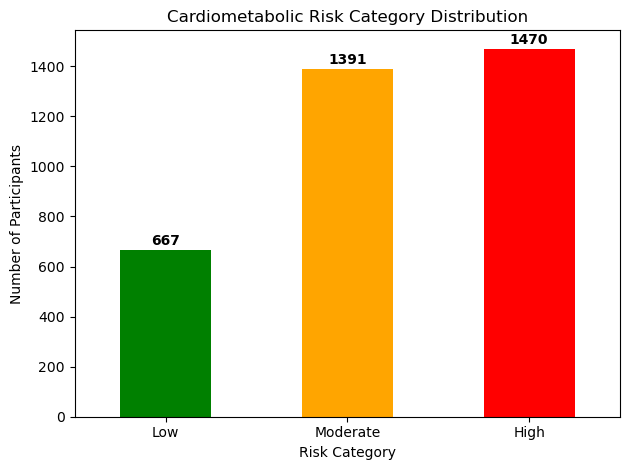

In [5]:
order = ['Low', 'Moderate', 'High']
colors = ['green', 'orange', 'red']

counts = df['Risk_category'].value_counts()[order]
ax = counts.plot(kind='bar', color=colors)
plt.title('Cardiometabolic Risk Category Distribution')
plt.xlabel('Risk Category')
plt.ylabel('Number of Participants')
plt.xticks(rotation=0)

for i, value in enumerate(counts):
    plt.text(i, value + 20, str(value), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('risk_distribution.png', dpi=150)
plt.show()

## 2. Age Distribution by Risk Category

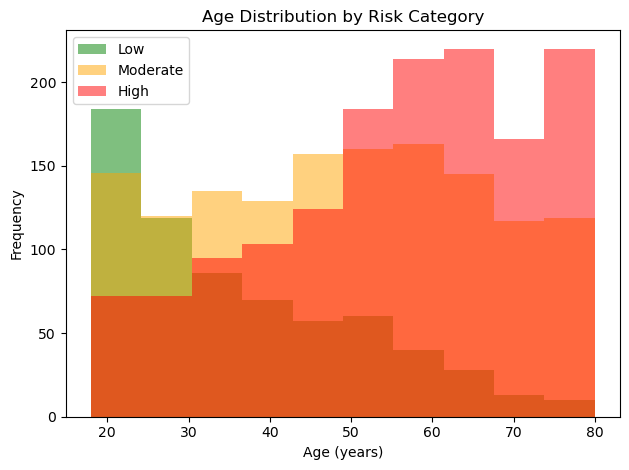

In [6]:
df[df['Risk_category'] == 'Low']['Age'].plot(kind='hist', alpha=0.5, label='Low', color='green')
df[df['Risk_category'] == 'Moderate']['Age'].plot(kind='hist', alpha=0.5, label='Moderate', color='orange')
df[df['Risk_category'] == 'High']['Age'].plot(kind='hist', alpha=0.5, label='High', color='red')

plt.title('Age Distribution by Risk Category')
plt.xlabel('Age (years)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.savefig('age_distribution.png', dpi=150)
plt.show()

## 3. Clinical Variable Boxplots by Risk Category

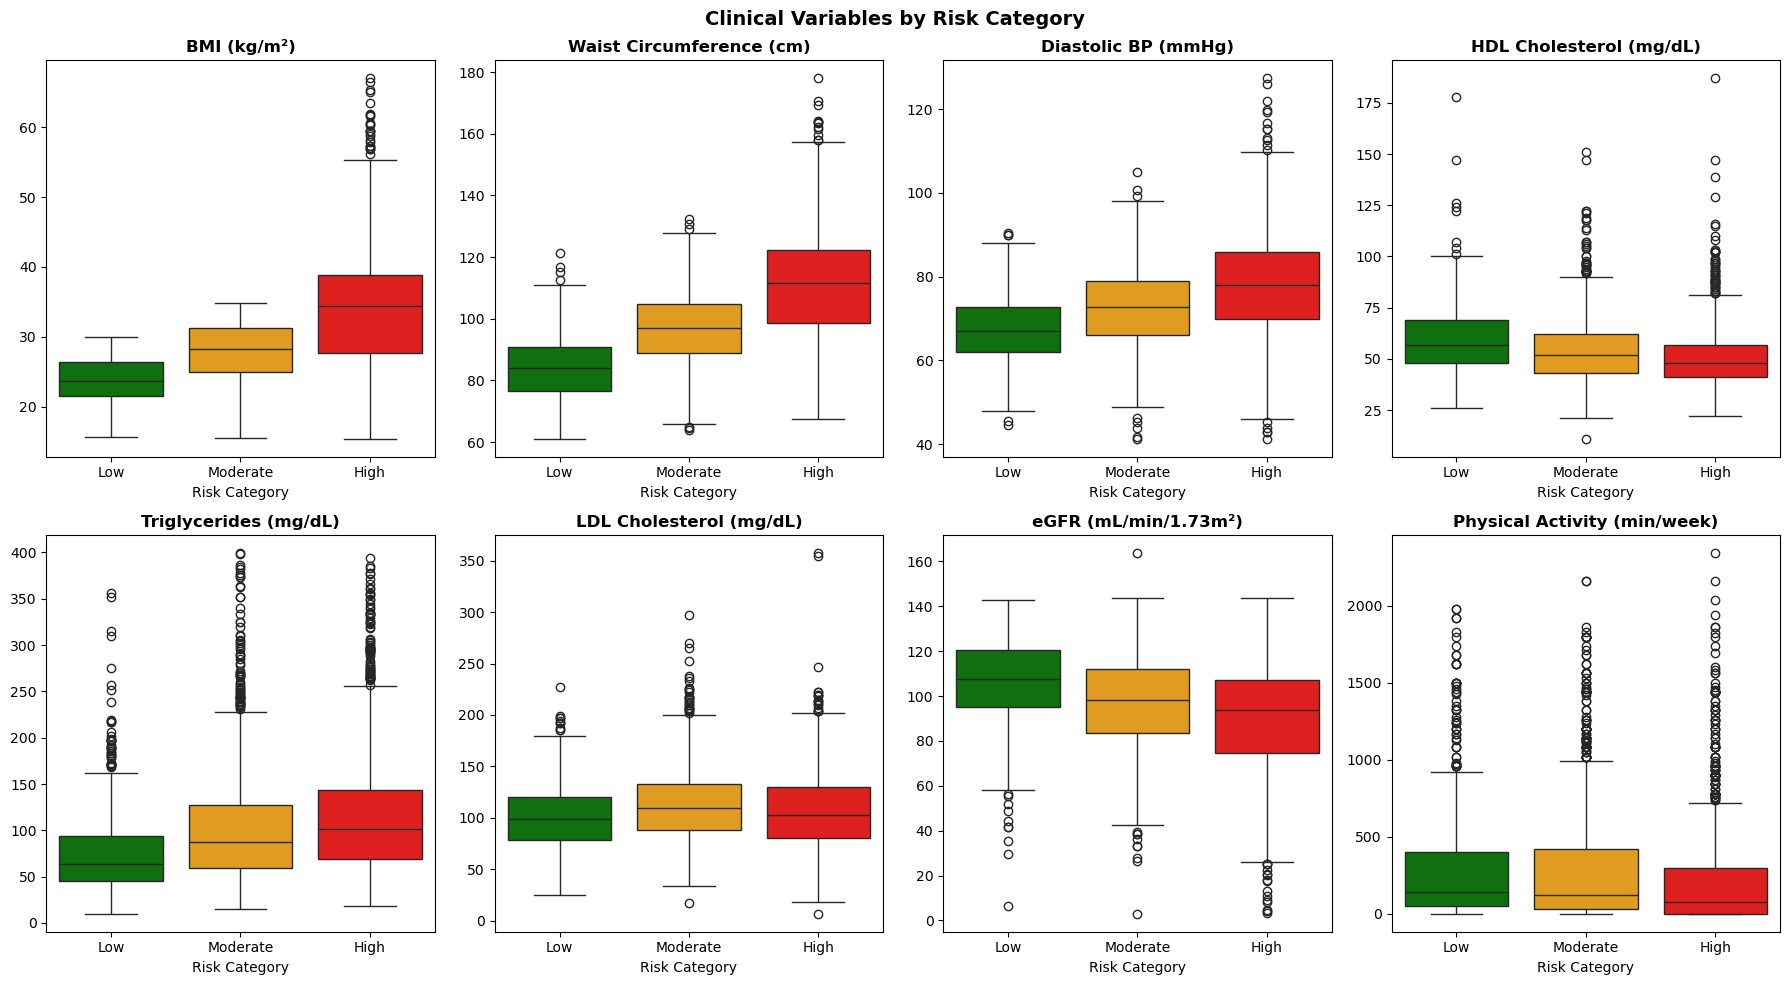

In [8]:
order = ['Low', 'Moderate', 'High']
colors = ['green', 'orange', 'red']

clinical_vars = [
    ('BMI', 'BMI (kg/m²)'),
    ('Waist_Circumference', 'Waist Circumference (cm)'),
    ('Diastolic_BP', 'Diastolic BP (mmHg)'),
    ('HDL_Cholesterol', 'HDL Cholesterol (mg/dL)'),
    ('Triglycerides', 'Triglycerides (mg/dL)'),
    ('LDL_Cholesterol', 'LDL Cholesterol (mg/dL)'),
    ('eGFR', 'eGFR (mL/min/1.73m²)'),
    ('Total_PA_Minutes', 'Physical Activity (min/week)')
]

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for ax, (var, label) in zip(axes, clinical_vars):
    sns.boxplot(data=df, x='Risk_category', y=var,
                order=order, palette=colors, ax=ax)
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('Risk Category')
    ax.set_ylabel('')

plt.suptitle('Clinical Variables by Risk Category', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('boxplots_clinical.png', dpi=150)
plt.show()

## 4. Correlation Heatmap

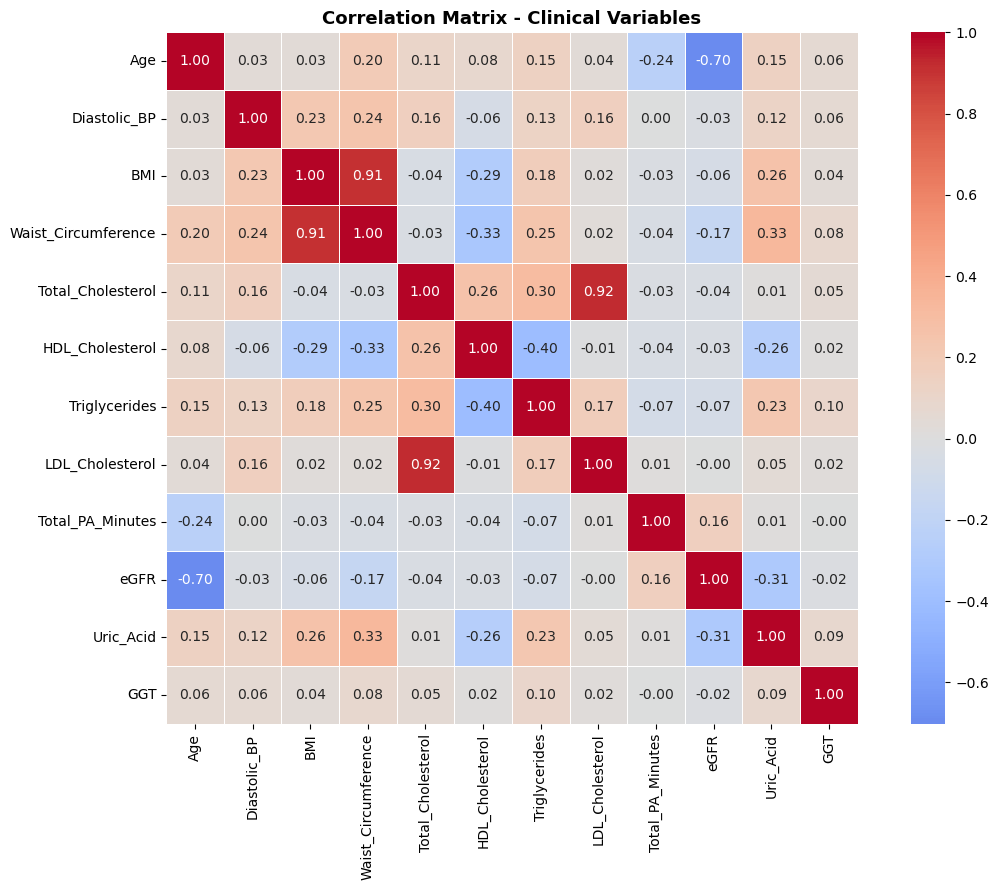

In [16]:
numeric_cols = ['Age', 'Diastolic_BP', 'BMI', 'Waist_Circumference',
                'Total_Cholesterol', 'HDL_Cholesterol', 'Triglycerides',
                'LDL_Cholesterol', 'Total_PA_Minutes', 'eGFR',
                'Uric_Acid', 'GGT']

plt.figure(figsize=(12, 9))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5)
plt.title('Correlation Matrix - Clinical Variables', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150)
plt.show()

## 5. Demographic Analysis

In [10]:
# Gender crosstab
gender_crosstab = pd.crosstab(df['Gender'], df['Risk_category'])
print("Risk Category by Gender:")
print(gender_crosstab)
print()

# Gender percentages
gender_pct = pd.crosstab(df['Gender'], df['Risk_category'], normalize='index') * 100
print("Percentages:")
print(gender_pct.round(1))

Risk Category by Gender:
Risk_category  High  Low  Moderate
Gender                            
Female          767  396       620
Male            703  271       771

Percentages:
Risk_category  High   Low  Moderate
Gender                             
Female         43.0  22.2      34.8
Male           40.3  15.5      44.2


In [11]:
# Race crosstab
race_crosstab = pd.crosstab(df['Race'], df['Risk_category'])
race_pct = pd.crosstab(df['Race'], df['Risk_category'], normalize='index') * 100

print("Risk Category by Race/Ethnicity (%):")
print(race_pct.round(1))

Risk Category by Race/Ethnicity (%):
Risk_category       High   Low  Moderate
Race                                    
Mexican American    41.9  15.2      43.0
Non-Hispanic Asian  29.6  25.1      45.3
Non-Hispanic Black  54.1  14.8      31.1
Non-Hispanic White  37.0  21.4      41.6
Other Hispanic      43.3  16.4      40.2
Other/Multi-Racial  36.8  21.8      41.5


## 6. Smoking Status Distribution

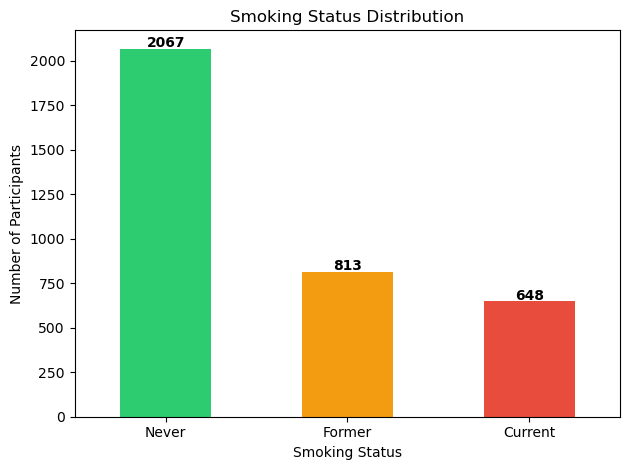

In [12]:
smoking_order = ['Never', 'Former', 'Current']
smoking_counts = df['Smoking_Status'].value_counts()[smoking_order]

smoking_counts.plot(kind='bar', color=['#2ecc71', '#f39c12', '#e74c3c'])
plt.title('Smoking Status Distribution')
plt.xlabel('Smoking Status')
plt.ylabel('Number of Participants')
plt.xticks(rotation=0)

for i, value in enumerate(smoking_counts):
    plt.text(i, value + 10, str(value), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('smoking_distribution.png', dpi=150)
plt.show()

## 7. eGFR Stage Distribution

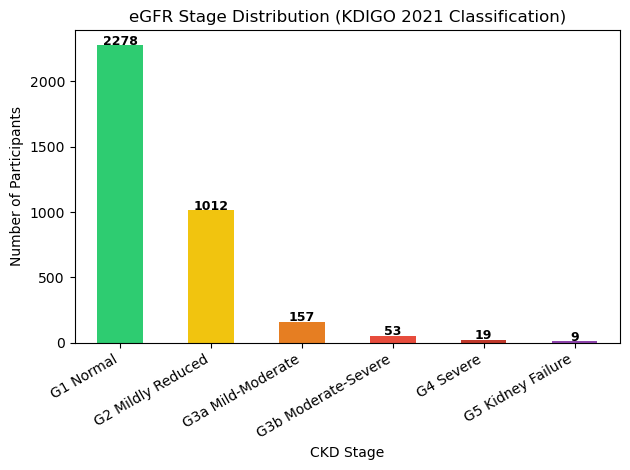

In [13]:
def egfr_stage(egfr):
    if egfr >= 90: return 'G1 Normal'
    elif egfr >= 60: return 'G2 Mildly Reduced'
    elif egfr >= 45: return 'G3a Mild-Moderate'
    elif egfr >= 30: return 'G3b Moderate-Severe'
    elif egfr >= 15: return 'G4 Severe'
    else: return 'G5 Kidney Failure'

df['eGFR_Stage'] = df['eGFR'].apply(egfr_stage)

stage_order = ['G1 Normal', 'G2 Mildly Reduced', 'G3a Mild-Moderate',
               'G3b Moderate-Severe', 'G4 Severe', 'G5 Kidney Failure']
stage_colors = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c', '#c0392b', '#8e44ad']

stage_counts = df['eGFR_Stage'].value_counts()[stage_order]
stage_counts.plot(kind='bar', color=stage_colors)
plt.title('eGFR Stage Distribution (KDIGO 2021 Classification)')
plt.xlabel('CKD Stage')
plt.ylabel('Number of Participants')
plt.xticks(rotation=30, ha='right')

for i, value in enumerate(stage_counts):
    plt.text(i, value + 5, str(value), ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('egfr_distribution.png', dpi=150)
plt.show()

## 8. Dataset Summary Statistics

In [15]:
numeric_summary = df[['Age', 'Diastolic_BP', 'BMI', 'Waist_Circumference',
                       'HbA1c', 'Fasting_Glucose', 'Total_Cholesterol',
                       'HDL_Cholesterol', 'Triglycerides', 'LDL_Cholesterol',
                       'eGFR', 'Total_PA_Minutes']].describe().round(2)

print("Descriptive Statistics:")
numeric_summary

Descriptive Statistics:


,Age,Diastolic_BP,BMI,Waist_Circumference,HbA1c,Fasting_Glucose,Total_Cholesterol,HDL_Cholesterol,Triglycerides,LDL_Cholesterol,eGFR,Total_PA_Minutes
count,3528.00,3528.00,3528.00,3528.00,3528.00,3528.00,3528.00,3528.00,3528.00,3528.00,3528.00,3528.00
mean,49.26,74.09,29.71,100.30,5.84,112.25,182.58,53.69,103.79,108.13,95.71,261.09
std,18.05,11.38,7.32,17.42,1.13,36.60,40.96,15.78,62.96,35.79,22.37,364.07
min,18.00,41.33,15.40,61.10,2.80,47.00,76.00,11.00,10.00,7.00,3.00,0.00
25%,33.00,66.00,24.60,87.80,5.30,96.00,154.00,42.00,59.00,83.00,81.70,20.00
50%,51.00,73.33,28.50,98.80,5.60,103.00,179.00,51.00,87.00,105.00,98.40,120.00
75%,63.00,81.00,33.50,111.30,6.00,114.00,207.00,61.00,130.00,129.00,112.10,360.00
max,80.00,127.33,67.00,178.00,15.20,451.00,446.00,187.00,399.00,357.00,163.60,2340.00
